In [10]:
import os, sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from transformers import AutoTokenizer
from src.data import load_ledgar


In [ ]:
os.chdir("..")              
sys.path.insert(0, os.getcwd())
print(os.getcwd())         

c:\Users\gabyd\contract-clause-nlp


Matplotlib is building the font cache; this may take a moment.
c:\Users\gabyd\contract-clause-nlp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 10000
    })
})
most frequent: Governing Laws 3167
least frequent: Books 23
imbalance ratio: 137.69565217391303


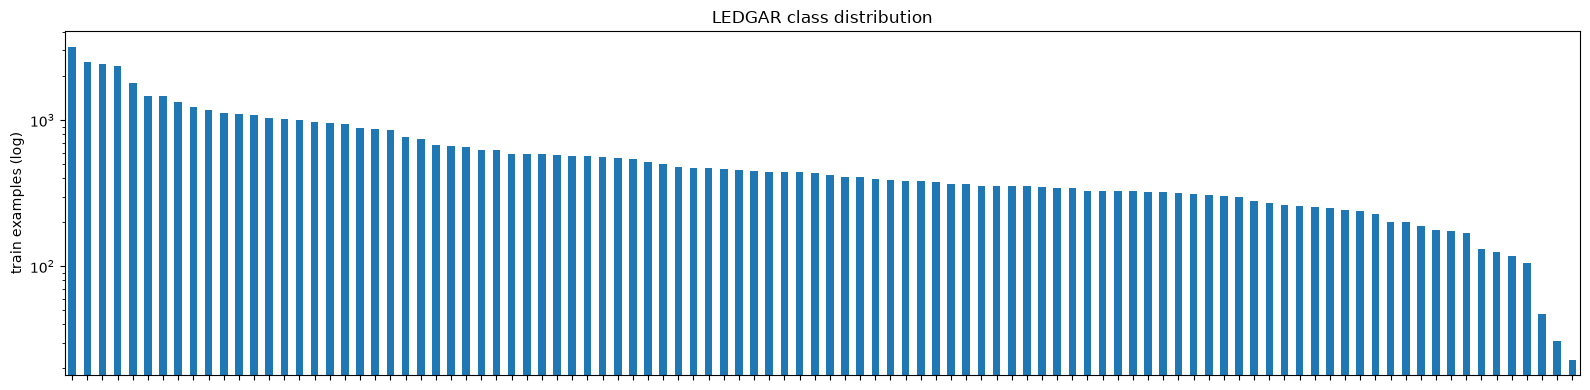

In [ ]:
ds, names = load_ledgar()
print(ds)

df = {s: ds[s].to_pandas() for s in ["train", "validation", "test"]}
counts = pd.Series(np.bincount(df["train"].label, minlength=len(names)), index=names).sort_values(ascending=False)
print("most frequent:", counts.index[0], counts.iloc[0])
print("least frequent:", counts.index[-1], counts.iloc[-1])
print("imbalance ratio:", counts.iloc[0] / counts.iloc[-1])

ax = counts.plot(kind="bar", figsize=(16, 4), logy=True)
ax.set_xticklabels([]); ax.set_ylabel("train examples (log)"); ax.set_title("LEDGAR class distribution")
plt.tight_layout(); plt.savefig("results/figures/class_distribution.png", dpi=150)

In [ ]:
print("Top 10:\n", counts.head(10), "\n")
print("Bottom 10:\n", counts.tail(10))

buckets = {
    "head":  counts.index[:20].tolist(),    # 20 most frequent types
    "torso": counts.index[20:60].tolist(),  # next 40
    "tail":  counts.index[60:].tolist(),    # 40 rarest
}
for b, labels in buckets.items():
    print(f"{b}: {len(labels)} classes, {counts[labels].sum()} train examples "
          f"({counts[labels].sum() / counts.sum():.1%})")

with open("results/class_buckets.json", "w") as f:
    json.dump(buckets, f, indent=2)

Top 10:
 Governing Laws       3167
Notices              2493
Counterparts         2427
Entire Agreements    2340
Severability         1808
Survival             1469
Amendments           1467
Assignments          1327
Expenses             1224
Terms                1166
dtype: int64 

Bottom 10:
 Approvals                  178
Consent To Jurisdiction    175
Costs                      168
Venues                     131
Powers                     125
Sanctions                  118
Anti-Corruption Laws       106
Qualifications              47
Assigns                     31
Books                       23
dtype: int64
head: 20 classes, 28998 train examples (48.3%)
torso: 40 classes, 21076 train examples (35.1%)
tail: 40 classes, 9926 train examples (16.5%)


In [7]:
for s in ["validation", "test"]:
    c = np.bincount(df[s].label, minlength=len(names))
    print(f"{s}: classes with 0 examples = {(c == 0).sum()}, with <10 examples = {(c < 10).sum()}")

validation: classes with 0 examples = 1, with <10 examples = 3
test: classes with 0 examples = 0, with <10 examples = 3


In [8]:
for s in ["validation", "test"]:
    c = pd.Series(np.bincount(df[s].label, minlength=len(names)), index=names)
    print(f"{s}: {c[c < 10].sort_values().to_dict()}")

validation: {'Books': 0, 'Assigns': 3, 'Qualifications': 8}
test: {'Books': 2, 'Assigns': 4, 'Qualifications': 5}


In [11]:
tok = AutoTokenizer.from_pretrained("nlpaueb/legal-bert-base-uncased")

lens = df["train"].text.sample(5000, random_state=0).map(lambda t: len(tok(t)["input_ids"]))

print(lens.describe(percentiles=[.5, .9, .95, .99]))

for L in [128, 256, 512]:
    print(f"% truncated at {L}: {(lens > L).mean():.1%}")

c:\Users\gabyd\contract-clause-nlp\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\gabyd\.cache\huggingface\hub\models--nlpaueb--legal-bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
[transformers] Token indices sequence length is longer than the specified maximum sequence lengt

count    5000.000000
mean      137.120400
std       120.752415
min         6.000000
50%       101.000000
90%       278.100000
95%       367.050000
99%       618.020000
max      1478.000000
Name: text, dtype: float64
% truncated at 128: 38.9%
% truncated at 256: 12.6%
% truncated at 512: 1.8%


In [ ]:
lens_all = [len(x) for x in tok(df["train"].text.tolist(), truncation=False)["input_ids"]]

df["train"]["n_tokens"] = lens_all
df["train"]["label_name"] = df["train"].label.map(lambda i: names[i])

trunc = (df["train"].assign(cut=df["train"].n_tokens > 256)
         .groupby("label_name")
         .agg(n=("cut", "size"), pct_cut=("cut", "mean"), median_tokens=("n_tokens", "median"))
         .sort_values("pct_cut", ascending=False))
print(trunc.head(10))

trunc.to_csv("results/truncation_by_class.csv")

                         n   pct_cut  median_tokens
label_name                                         
Capitalization         434  0.684332          382.0
Confidentiality       1012  0.445652          225.5
No Conflicts           741  0.431849          237.0
Indemnity              271  0.424354          215.0
Publicity              345  0.388406          195.0
Participations         459  0.387800          231.0
Financial Statements   677  0.378139          194.0
Releases               621  0.352657          201.0
Indemnifications       936  0.348291          187.0
Arbitration            385  0.345455          174.0


In [ ]:
norm = lambda s: " ".join(s.lower().split())
tr = set(df["train"].text.map(norm))
te = df["test"].text.map(norm)

print("duplicate texts inside train:", len(df["train"]) - len(tr))
print("test clauses also in train:", te.isin(tr).sum(), f"({te.isin(tr).mean():.1%})")

duplicate texts inside train: 920
test clauses also in train: 282 (2.8%)


In [16]:
dup_idx = np.where(te.isin(tr))[0].tolist()
json.dump(dup_idx, open("results/test_duplicate_idx.json", "w"))

In [14]:
d = df["train"].assign(norm=df["train"].text.map(norm))

n_labels = d.groupby("norm").label.nunique()
conflicts = n_labels[n_labels > 1]

print("identical texts with different labels:", len(conflicts))

for t in conflicts.index[:5]:
    labs = sorted({names[l] for l in d[d.norm == t].label})
    print(labs, "|", t[:150], "\n")

identical texts with different labels: 3
['No Waivers', 'Waivers'] | the failure of a party to insist upon strict adherence to any term of this agreement on any occasion shall not be considered a waiver of such party’s  

['Existence', 'Qualifications'] | the general partner and each of the partnership entities has been duly formed and is validly existing and in good standing under the laws of the state 

['Applicable Laws', 'Governing Laws'] | this agreement shall be governed by and construed in accordance with the laws of the state of new york applicable to contracts made and to be performe 



- Finding 3: clause length.
Median 101 tokens; 12.6% exceed 256 and 1.8% exceed 512. Truncation is concentrated in a few types: 68% of Capitalization clauses and about 40% of Confidentiality, No Conflicts and Indemnity clauses exceed 256. Decision: max_length = 256 for the main runs; the audit measures F1 on long clauses and these types to check whether the cut hurts.

- Finding 4: duplicates and leakage. 
920 duplicates inside train; 282 test clauses (2.8%) also appear in train. Decision: report test scores on the full and the de-duplicated test set.

- Finding 5: label noise. 
Identical texts carry different labels (Waivers / No Waivers, Applicable Laws / Governing Laws, Existence / Qualifications). Some clause types overlap in meaning, which limits the maximum achievable accuracy for those types.